## Dans ce notebook, nous verrons :
1. L'influence de l'apprentissage sur plusieurs capteurs
2. Comment entrainer notre modèle à débruiter un signal : on passera d'un Auto-Encodeur (AE) à un Denoising Auto-Encodeur (DAE)

In [1]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


I0000 00:00:1795601242.985583   47447 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, confusion_matrix
from keras.callbacks import EarlyStopping
from Sources import data, config, features, models

DUREE_FENETRE = config.DUREE_FENETRE

def construire_fenetres_brutes(selection, canal="DE", duree=config.DUREE_FENETRE, recouvrement=0.5):
    SB, lignes = [], []
    for nom, info in selection.iterrows():
        s = data.charger(nom, canaux=(canal,))
        for i, val in enumerate(features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)):
            SB.append(val)
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"],
                           "defaut_sain": "Sain" if info["defaut"] == "Sain" else "Défaut",
                           "diametre_mils": info["diametre_mils"],
                           "classe": "Sain" if info["defaut"] == "Sain" else info["defaut"] + str(info["diametre_mils"]).zfill(3)})
    return np.array(SB, dtype=np.float32), pd.DataFrame(lignes)

def score_mse(modele, X):
    Xr = modele.predict(X[..., None], verbose=0)[..., 0]
    return ((X - Xr) ** 2).mean(axis=1)

def ajouter_bruit(x, snr_db, seed=42):
    rng = np.random.default_rng(seed)
    p = np.mean(x ** 2)
    return x + np.sqrt(p / 10 ** (snr_db / 10)) * rng.standard_normal(x.shape)

# --- DE + FE ---
selection_DE = data.selectionner(sources=("12kDE", "Normal"), defauts=("IR","B","OR"),
                                 diametres=(7,14,21), positions_or=("6",), charges=(0,1,2,3),
                                 canaux={"12kDE": ("DE",), "Normal": ("DE",)})
selection_FE = data.selectionner(sources=("12kFE", "Normal"), defauts=("IR","B","OR"),
                                 diametres=(7,14,21), positions_or=("3","6","12"), charges=(0,1,2,3),
                                 canaux={"12kFE": ("FE",), "Normal": ("FE",)})
SB_DE, infos_DE = construire_fenetres_brutes(selection_DE, canal="DE")
SB_FE, infos_FE = construire_fenetres_brutes(selection_FE, canal="FE")

SB = np.concatenate([SB_DE, SB_FE], axis=0)
infos = pd.concat([infos_DE, infos_FE], ignore_index=True)

print(SB.shape); print(infos.groupby(["canal", "defaut_sain"]).size())

(12804, 2048)
canal  defaut_sain
DE     Défaut         4234
       Sain           1653
FE     Défaut         5264
       Sain           1653
dtype: int64


In [6]:
from sklearn.model_selection import StratifiedGroupKFold

sain = (infos["defaut_sain"] == "Sain").to_numpy()

# Split par FICHIER entier, stratifié sain/défaut -> fichiers sains garantis au test (DE et FE)
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=40)
i_train, i_test = next(cv.split(infos, infos["defaut_sain"], groups=infos["fichier"]))

assert len(np.intersect1d(infos["fichier"].to_numpy()[i_train],
                          infos["fichier"].to_numpy()[i_test])) == 0, "fuite : un fichier est des deux côtés"
assert sain[i_test].any() and ((infos["canal"].to_numpy() == "FE") & sain)[i_test].any()

SBNorm = features.standardiser_par_fenetre(SB)            # sans état, après le split
X_train_sain = SBNorm[i_train][sain[i_train]]

In [7]:
pd.DataFrame({
    "train": infos.iloc[i_train[sain[i_train]]][["defaut_sain","canal"]].value_counts(),
    "test":  infos.iloc[i_test][["defaut_sain","canal"]].value_counts(),
}).fillna(0).astype(int)

train  test
defaut_sain canal             
Défaut      DE         0  1058
            FE         0  1287
Sain        DE      1180   473
            FE      1180   473

In [8]:
def evaluer_par_capteur(modele, tag):
    score = score_mse(modele, SBNorm)
    seuil = np.percentile(score[i_train][sain[i_train]], 99)
    s_test, y = score[i_test], (infos["defaut_sain"].to_numpy()[i_test] == "Défaut").astype(int)
    c = infos["canal"].to_numpy()[i_test]
    lignes = []
    for canal in ["DE", "FE"]:
        m = c == canal
        TN, FP, FN, TP = confusion_matrix(y[m], s_test[m] > seuil, labels=[0, 1]).ravel()
        lignes.append({"config": tag, "capteur": canal, "seuil_p99": round(float(seuil), 4),
                       "AUC": round(roc_auc_score(y[m], s_test[m]), 3),
                       "FPR": round(FP/(FP+TN), 4), "FNR": round(FN/(FN+TP), 4)})
    return pd.DataFrame(lignes)

modele_AE = models.conv1d_ae(SBNorm.shape[1])
modele_AE.fit(X_train_sain[..., None], X_train_sain[..., None], epochs=50, batch_size=64,
              validation_split=0.1, verbose=1,
              callbacks=[EarlyStopping(monitor="val_loss", patience=5, min_delta=0.02, restore_best_weights=True)])
df_AE = evaluer_par_capteur(modele_AE, "AE (sains DE+FE)")
display(df_AE)

Epoch 1/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 11s 226ms/step - loss: 0.4149 - val_loss: 0.2706
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 174ms/step - loss: 0.1688 - val_loss: 0.2135
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 175ms/step - loss: 0.0809 - val_loss: 0.0354
Epoch 4/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 168ms/step - loss: 0.0244 - val_loss: 0.0243
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 179ms/step - loss: 0.0185 - val_loss: 0.0199
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - loss: 0.0158 - val_loss: 0.0172
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 10s 170ms/step - loss: 0.0145 - val_loss: 0.0165
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 170ms/step - loss: 0.0132 - val_loss: 0.0164


W0000 00:00:1795601318.438060   47447 cpu_allocator_impl.cc:174] Allocation of 104890368 exceeds 10% of free system memory.
W0000 00:00:1795601328.793339   47447 cpu_allocator_impl.cc:174] Allocation of 104890368 exceeds 10% of free system memory.


,config,capteur,seuil_p99,AUC,FPR,FNR
0,AE (sains DE+FE),DE,0.0411,1.0,0.0063,0.0
1,AE (sains DE+FE),FE,0.0411,1.0,0.0085,0.0


In [9]:
# Data augmentation : on duplique le train sain bruité, cible = propre
X_aug, Y_aug = [X_train_sain], [X_train_sain]
for snr in [15, 10, 5, 0]:
    X_aug.append(ajouter_bruit(X_train_sain, snr, seed=snr))
    Y_aug.append(X_train_sain)
X_aug, Y_aug = np.concatenate(X_aug), np.concatenate(Y_aug)

modele_DAE = models.conv1d_ae(SBNorm.shape[1])
modele_DAE.fit(X_aug[..., None], Y_aug[..., None], epochs=50, batch_size=64,
               validation_split=0.1, verbose=1,
               callbacks=[EarlyStopping(monitor="val_loss", patience=5, min_delta=0.02, restore_best_weights=True)])
df_DAE = evaluer_par_capteur(modele_DAE, "DAE (aug SNR 15..0)")
display(df_DAE)

display(pd.concat([df_AE, df_DAE]).set_index(["config", "capteur"]))

W0000 00:00:1795601331.456241   47447 cpu_allocator_impl.cc:174] Allocation of 86999040 exceeds 10% of free system memory.


Epoch 1/50


W0000 00:00:1795601333.044619   47447 cpu_allocator_impl.cc:174] Allocation of 86999040 exceeds 10% of free system memory.


166/166 ━━━━━━━━━━━━━━━━━━━━ 32s 174ms/step - loss: 0.2225 - val_loss: 0.2729
Epoch 2/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 30s 183ms/step - loss: 0.0740 - val_loss: 0.2409
Epoch 3/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 168ms/step - loss: 0.0670 - val_loss: 0.2263
Epoch 4/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 168ms/step - loss: 0.0639 - val_loss: 0.2170
Epoch 5/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 29s 177ms/step - loss: 0.0619 - val_loss: 0.2133
Epoch 6/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 29s 172ms/step - loss: 0.0605 - val_loss: 0.2098
Epoch 7/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 169ms/step - loss: 0.0594 - val_loss: 0.2071
Epoch 8/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 171ms/step - loss: 0.0588 - val_loss: 0.2055
Epoch 9/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 30s 182ms/step - loss: 0.0581 - val_loss: 0.2046


W0000 00:00:1795601597.286357   47447 cpu_allocator_impl.cc:174] Allocation of 104890368 exceeds 10% of free system memory.


,config,capteur,seuil_p99,AUC,FPR,FNR
0,DAE (aug SNR 15..0),DE,0.0173,1.0,0.0021,0.0
1,DAE (aug SNR 15..0),FE,0.0173,1.0,0.0190,0.0


seuil_p99  AUC     FPR  FNR
config              capteur                             
AE (sains DE+FE)    DE          0.0411  1.0  0.0063  0.0
                    FE          0.0411  1.0  0.0085  0.0
DAE (aug SNR 15..0) DE          0.0173  1.0  0.0021  0.0
                    FE          0.0173  1.0  0.0190  0.0

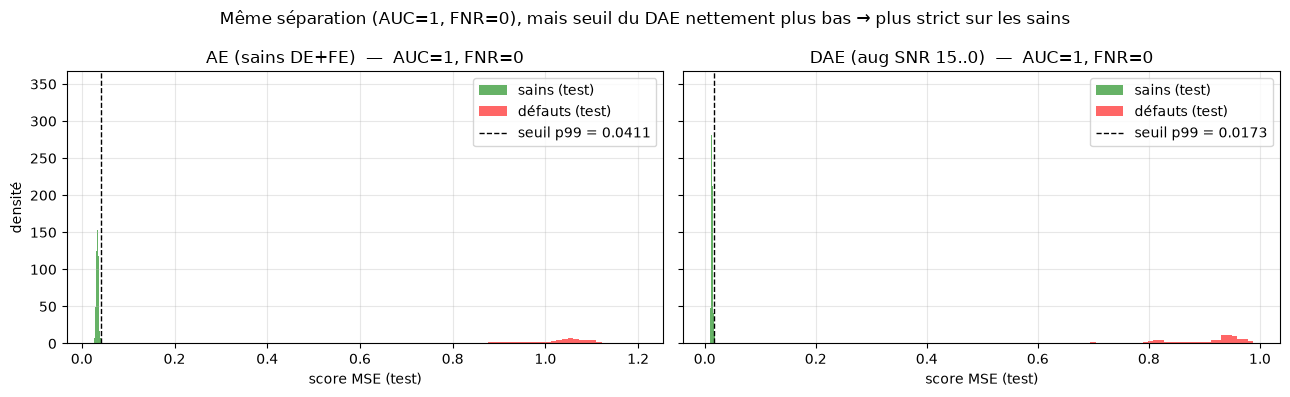

In [10]:
# === Illustration : seuil DAE plus bas, séparation identique ===
y_test = (infos["defaut_sain"].to_numpy()[i_test] == "Défaut")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, modele, tag in [(axes[0], modele_AE, "AE (sains DE+FE)"),
                        (axes[1], modele_DAE, "DAE (aug SNR 15..0)")]:
    score = score_mse(modele, SBNorm)
    seuil = np.percentile(score[i_train][sain[i_train]], 99)      # p99 du train sain
    s = score[i_test]
    ax.hist(s[~y_test], bins=60, density=True, alpha=0.6, color="green", label="sains (test)")
    ax.hist(s[y_test],  bins=60, density=True, alpha=0.6, color="red",   label="défauts (test)")
    ax.axvline(seuil, color="black", ls="--", lw=1, label=f"seuil p99 = {seuil:.4f}")
    ax.set_title(f"{tag}  —  AUC=1, FNR=0"); ax.set_xlabel("score MSE (test)")
    ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("densité")
fig.suptitle("Même séparation (AUC=1, FNR=0), mais seuil du DAE nettement plus bas → plus strict sur les sains")
plt.tight_layout(); plt.show()

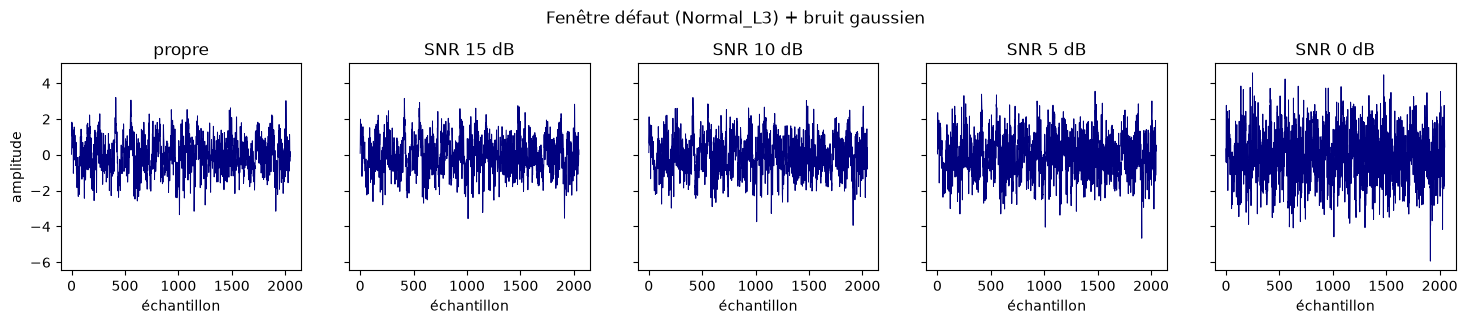

In [11]:
#| label: fig-bruit
#| fig-cap: "Même fenêtre défaut à différents SNR (bruit gaussien ajouté) : propre, 15, 10, 5, 0 dB."
# i_def = i_test[~sain[i_test]][520]                 # une fenêtre défaut du test
i_def = i_test[sain[i_test]][0]                 # une fenêtre défaut du test
x = SBNorm[i_def]

niveaux = [None, 15, 10, 5, 0]                    # None = signal propre
titres  = ["propre", "SNR 15 dB", "SNR 10 dB", "SNR 5 dB", "SNR 0 dB"]

fig, axes = plt.subplots(1, 5, figsize=(18, 3), sharex=True, sharey=True)   # mêmes échelles
for ax, snr, titre in zip(axes, niveaux, titres):
    xb = x if snr is None else ajouter_bruit(x, snr, seed=42)   # même bruit reproductible
    ax.plot(xb, color="navy", lw=0.7)
    ax.set_title(titre); ax.set_xlabel("échantillon")
axes[0].set_ylabel("amplitude")
fig.suptitle(f"Fenêtre défaut ({infos.loc[i_def, 'fichier']}) + bruit gaussien")
plt.subplots_adjust(top=0.80)
plt.show()